# Próg wejścia a zarobki: które stanowisko w branży danych opłaca się najbardziej?

## Wprowadzenie
**Cel:** sprawdzenie, co wiąże się z wysokością zarobków w branży danych i na którym stanowisku można stosunkowo dużo zarabiać przy względnie łatwym wejściu do zawodu.

**Łatwość wejścia:** wejście uznaję za łatwiejsze, gdy na danym stanowisku jest więcej:

1. osób, które przysy spoza branży,
2. juniorów,
3. osób bez dyplomu studiów lub po kierunkach nietechnicznych,

a sama praca wymaga mniej programowania i mniejszej liczby narzędzi.

Na potrzeby tej analizy przyjmijmy, że „stosunkowo dużo zarabiać” oznacza medianę zarobków na danym stanowisku wyższą od mediany wszystkich osób na tym samym poziomie seniority. Wyniki dla grup liczących mniej niż ok. 20 osób mają charakter orientacyjny.

### Plan projektu

1. Przygotowanie danych: wczytanie ich i połączenie trzech plików.
2. Opis próby.
3. Sprawdzenie zarobków: analiza rozkładu, braków i wartości nietypowych.
4. Czynniki związane z zarobkami.
5. Wskaźniki progu wejścia.
6. Zbudowanie indeksu progu wejścia: połączenie wskaźników w jedną liczbę.
7. Próg wejścia a zarobki.
8. Sprawdzenie stabilności wyniku. Czy zwycięzca zmienia się przy innych miarach?
9. Wnioski końcowe: odpowiedź na pytanie z tytułu i opis ograniczeń

### Kolumny użyte w analizie

**Podstawa**
- `id`: łączenie plików
- `stanowisko`: główny podział analizy
- `zarobki`: zmienna, którą wyjaśniam

**Próg wejścia**
- Osoby spoza branży: `czy przed objęciem obecnego stanowiska pracowałeś/aś już w branży it lub analitycznej`
- Juniorzy: `poziom stanowiska (seniority)`
- Dyplom studiów: `wykształcenie__licencjat`, `wykształcenie__inżynier`, `wykształcenie__magister`, `wykształcenie__doktorat`
- Kierunek studiów: `kierunek wykształcenia`
- Ilość programowania: `jaki procent twojej pracy stanowi programowanie` (skala 1–10)
- Liczba narzędzi: kolumny zaczynające się od `narzędzia |`

**Czynniki wpływające na zarobki**
- Stanowisko i doświadczenie: `poziom stanowiska (seniority)`, `lata doświadczenia`
- Forma zatrudnienia: `w jakiej formie jesteś obecnie zatrudniony/a`
- Firma: `wielkość firmy, w której pracujesz`, `jaki kapitał ma firma, w której pracujesz`
- Osoba: `płeć`, `miejsce zamieszkania`, `kierunek wykształcenia`, `wykształcenie__doktorat`

## 1. Wczytanie i połączenie danych

In [2]:
# import bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# wczytanie danych
ogolne = pd.read_csv('Dane/0.df_ogolne.csv')
technologie = pd.read_csv('Dane/2.df_technologie.csv')
praca = pd.read_csv('Dane/4.df_organizacja_pracy.csv')
# połączenie danych w jeden DataFrame po kolumnie 'id'
df = ogolne.merge(technologie, on='id').merge(praca, on='id')

df.shape

(297, 109)

Trzy pliki po kolumnie `id` zostały połączone. Tabela zawiera 297 osób i 109 kolumn.

## 2. Opis próby.

In [3]:
print(f'Liczba osób w próbie: {len(df)}')

print('\nStanowiska:')
print(df['stanowisko'].value_counts())

print('\nWymiar pracy:')
print(df['wymiar pracy'].value_counts(dropna=False))

print('\nForma zatrudnienia:')
print(df['w jakiej formie jesteś obecnie zatrudniony/a'].value_counts(dropna=False))

Liczba osób w próbie: 297

Stanowiska:
stanowisko
data analyst                            162
data scientist                           39
data engineer                            33
business intelligence (bi) developer     26
business analyst                         20
ml/ai engineer                           13
analytics engineer                        4
Name: count, dtype: int64

Wymiar pracy:
wymiar pracy
pełny etat (ok. 40 godzin tygodniowo)                    278
praca w oparciu o rozliczanie godzinowe lub zadaniowe      9
część etatu                                                6
inne / trudno powiedzieć                                   4
Name: count, dtype: int64

Forma zatrudnienia:
w jakiej formie jesteś obecnie zatrudniony/a
umowa o pracę                243
b2b (samozatrudnienie)        39
umowa zlecenie / o dzieło      6
inne                           5
NaN                            4
Name: count, dtype: int64


Dane obejmują **297 osób** z branży danych:

- **Stanowiska:** najliczniejszą grupą są data analyści (162 osoby, 55% próby). Grupy ml/ai engineer (13 osób) i analytics engineer (4 osoby) są za małe na mocne wnioski.
- **Wymiar pracy:** zdecydowana większość osób pracuje na pełnym etacie (278 osób, 94%). Pozostałe formy (19 osób) są zbyt małe na osobne wnioski.
- **Zatrudnienie:** 278 osób (94%) pracuje na pełnym etacie, 243 (82%) na umowie o pracę, a 39 (13%) na B2B.

Analiza obejmuje wszystkie osoby, a wyniki dla mniej licznych grup mają charakter orientacyjny.

## 3. Zarobki: rozkład, braki i wartości nietypowe.

### A. Podstawowe statystyki

In [4]:
print(df['zarobki'].describe())

count      267.000000
mean      9455.655431
std       4033.319485
min       3834.000000
25%       6700.000000
50%       8500.000000
75%      11000.000000
max      31000.000000
Name: zarobki, dtype: float64


Średnie zarobki (ok. 9 456 ) są wyższe od mediany (8 500 ). Rozkład jest prawostronnie skośny: stosunkowo niewielka grupa osób z wysokimi zarobkami podnosi średnią. Dlatego w dalszych porównaniach używam mediany, która lepiej opisuje typowe wynagrodzenie.

### B. Histogram.

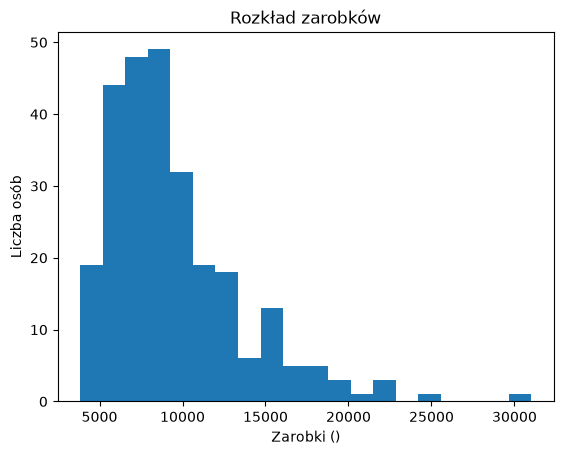

In [5]:
plt.hist(df['zarobki'].dropna(), bins=20)
plt.title('Rozkład zarobków')
plt.xlabel('Zarobki ()')
plt.ylabel('Liczba osób')
plt.show()

**Wnioski**

- **Typowe zarobki:** najwięcej osób zarabia mniej więcej od 5 000 do 9 000 . W tym zakresie słupki są najwyższe i mają podobną wysokość, po około 45–50 osób.
- **Kształt rozkładu:** rozkład jest prawostronnie skośny. Po lewej stronie szczytu słupki szybko się kończą, a po prawej stopniowo maleją i tworzą długi ogon.
- **Wysokie zarobki:** powyżej około 17 000  słupki są już bardzo niskie, więc tak wysokie zarobki ma niewiele osób.
- **Najwyższa wartość:** pojedyncza osoba zarabia około 31 000 . Od reszty danych oddziela ją wyraźna przerwa na wykresie, więc tę wartość warto sprawdzić.
- **Ograniczenie:** wykres obejmuje wszystkie stanowiska i formy zatrudnienia, więc nie wyjaśnia, skąd biorą się różnice w zarobkach.

### C. Braki danych

In [6]:
# Liczba braków danych w kolumnie 'zarobki'

print(f"Podali zarobki: {df['zarobki'].notna().sum()}")
print(f"Nie podali zarobków: {df['zarobki'].isna().sum()}")
print(f"Procent braków: {df['zarobki'].isna().mean() * 100:.1f}%")

Podali zarobki: 267
Nie podali zarobków: 30
Procent braków: 10.1%


In [7]:
# Procent braków w kolumnie 'zarobki' według stanowiska
print((df['zarobki'].isna().groupby(df['stanowisko']).mean() * 100).round(1))

stanowisko
analytics engineer                      25.0
business analyst                         5.0
business intelligence (bi) developer     3.8
data analyst                             8.0
data engineer                            6.1
data scientist                          15.4
ml/ai engineer                          46.2
Name: zarobki, dtype: float64


In [8]:
# Wpływ uzupełniania braków danych na statystyki opisowe kolumny 'zarobki'

porownanie = pd.DataFrame({
    'bez uzupełniania': df['zarobki'].describe(),
    'zero': df['zarobki'].fillna(0).describe(),
    'mediana': df['zarobki'].fillna(df['zarobki'].median()).describe()
})
print(porownanie.round(0))

       bez uzupełniania     zero  mediana
count             267.0    297.0    297.0
mean             9456.0   8501.0   9359.0
std              4033.0   4771.0   3834.0
min              3834.0      0.0   3834.0
25%              6700.0   6000.0   7000.0
50%              8500.0   8000.0   8500.0
75%             11000.0  10700.0  10700.0
max             31000.0  31000.0  31000.0


**Wnioski**

Zarobków nie podało **30 z 297 osób (10,1%)**, więc analizy wynagrodzeń opieram na **267 odpowiedziach**.

**Sposób postępowania:**
- Nie uzupełniam braków, np. medianą ani zerem, ponieważ zniekształciłoby to rozkład. Wpisanie zera obniżyłoby medianę zarobków z 8 500 do 8 000 , a wpisanie mediany sztucznie zmniejszyłoby rozrzut (odchylenie standardowe z 4 033 do 3 834 )
- Osoby bez podanych zarobków pomijam tylko w obliczeniach i na wykresach dotyczących wynagrodzeń.
- Te osoby pozostają w danych i uwzględniam je w pozostałych analizach, np. przy ocenie progu wejścia.

**Ograniczenie:** braki są nierówno roożone. Wśród ml/ai engineerów zarobków nie podało 46% osób (zostaje 7 z 13), dlatego wyniki dla tej grupy traktuję ostrożniej, ponieważ mogą nie być reprezentatywne.

### D. Wartości nietypowe.

#### Boxplot = Wykres Pudełkowy

Służy do wizualnego przedstawienia rozkładu danych oraz ich najważniejszych statystyk opisowych. Umozliwia **szybkie porównywanie grup** oraz **wykrywanie anomalii** w danych.

#### Pokazuje cechy takie jak:
* **Mediana** (pomarańczowa linia) – wartość środkowa zbioru.
* **Pudełko (IQR)** – obejmuje środkowe 50% danych (od Q1 do Q3), pokazując ich rozrzut.
* **Wąsy** – wyznaczają standardowy zakres danych.
* **Punkty poza wąsami** – wartości odstające (skrajnie nietypowe).

#### IQR
* Wysokość (lub szerokość) pudełka to dokładnie wartość IQR (czyli odległość między pierwszym kwartylem a trzecim kwartylem).
* Samo pudełko zawiera w sobie środkowe 50% danych z całego zbioru.

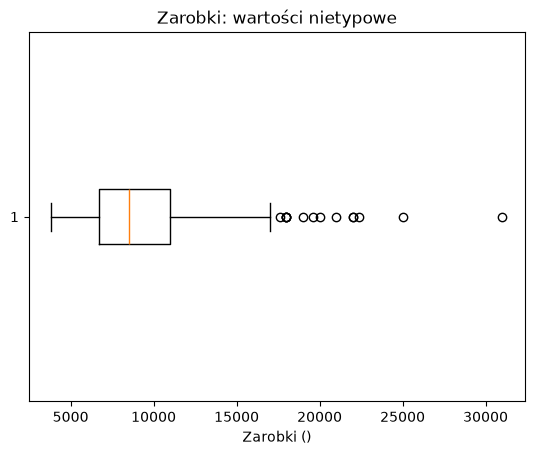

In [9]:
plt.boxplot(df['zarobki'].dropna(), orientation='horizontal')
plt.title('Zarobki: wartości nietypowe')
plt.xlabel('Zarobki ()')
plt.show()

#### Górna granica

Górna granica pomaga wskazać wartości odstające, czyli zarobki wyraźnie wyższe od pozostałych. Oznaczenie wartości nie przesądza, że jest ona błędna, dlatego warto sprawdzić, czy wygląda na prawdziwą, i dopiero wtedy zadecydować, czy ją zostawić.

In [10]:
q1 = df['zarobki'].quantile(0.25)
q3 = df['zarobki'].quantile(0.75)
gorna_granica = q3 + 1.5 * (q3 - q1)

kolumny = ['stanowisko', 'poziom stanowiska (seniority)',
           'w jakiej formie jesteś obecnie zatrudniony/a', 'zarobki']
wysokie = df[df['zarobki'] > gorna_granica]

print(f'Górna granica: {gorna_granica:.0f}')
print(f'Liczba osób powyżej górnej granicy: {len(wysokie)}')
wysokie[kolumny].sort_values('zarobki', ascending=False)


Górna granica: 17450
Liczba osób powyżej górnej granicy: 14


,stanowisko,poziom stanowiska (seniority),w jakiej formie jesteś obecnie zatrudniony/a,zarobki
263,data scientist,manager / team leader,b2b (samozatrudnienie),31000.0
273,business intelligence (bi) developer,senior,b2b (samozatrudnienie),25000.0
57,data engineer,mid / regular,b2b (samozatrudnienie),22400.0
20,data analyst,lead / expert,b2b (samozatrudnienie),22000.0
30,data scientist,senior,b2b (samozatrudnienie),22000.0
77,data analyst,manager / team leader,b2b (samozatrudnienie),21000.0
266,data scientist,senior,umowa o pracę,20000.0
178,data engineer,mid / regular,umowa o pracę,19600.0
286,data engineer,senior,b2b (samozatrudnienie),19000.0
164,business intelligence (bi) developer,senior,b2b (samozatrudnienie),18000.0


In [11]:
# Procent osób powyżej górnej granicy
procent = 14 / 267 * 100
print(f'Procent osób powyżej górnej granicy: {procent:.2f}%')

Procent osób powyżej górnej granicy: 5.24%


In [12]:
# Forma zatrudnienia osób powyżej górnej granicy
forma = 'w jakiej formie jesteś obecnie zatrudniony/a'
wysokie[forma].value_counts()

w jakiej formie jesteś obecnie zatrudniony/a
b2b (samozatrudnienie)    10
umowa o pracę              4
Name: count, dtype: int64

In [13]:
# Liczba osób na B2B, które podały zarobki
b2b_z_zarobkami = df[(df[forma] == 'b2b (samozatrudnienie)') & (df['zarobki'].notna())]
print(f'Liczba wszystkich osób na B2B, które podały zarobki: {len(b2b_z_zarobkami)}')

# Liczba osób na B2B, które są powyżej górnej granicy
b2b_wysokie = wysokie[wysokie[forma] == 'b2b (samozatrudnienie)']
print(f'Liczba osób na B2B, które są powyżej górnej granicy: {len(b2b_wysokie)}')

# Procent najlepiej zarabiających wśród osób na B2B
procent_b2b = len(b2b_wysokie) / len(b2b_z_zarobkami) * 100
print(f'Procent osób na B2B, które są powyżej górnej granicy: {procent_b2b:.2f}%')

Liczba wszystkich osób na B2B, które podały zarobki: 32
Liczba osób na B2B, które są powyżej górnej granicy: 10
Procent osób na B2B, które są powyżej górnej granicy: 31.25%


In [14]:
# Liczba wszystkich osób na umowie o pracę, które podały zarobki
umowa_o_prace = df[(df[forma] == 'umowa o pracę') & (df['zarobki'].notna())]
print(f'Liczba osób na umowie o pracę, które podały zarobki: {len(umowa_o_prace)}')

# liczba osób na umowie o pracę, które są powyżej górnej granicy
umowa_o_prace_wysokie = wysokie[wysokie[forma] == 'umowa o pracę']
print(f'Liczba osób na umowie o pracę, które są powyżej górnej granicy: {len(umowa_o_prace_wysokie)}')

# procent osób na umowie o pracę, które są powyżej górnej granicy
procent_umowa_o_prace = len(umowa_o_prace_wysokie) / len(umowa_o_prace) * 100   
print(f'Procent osób na umowie o pracę, które są powyżej górnej granicy: {procent_umowa_o_prace:.2f}%')

Liczba osób na umowie o pracę, które podały zarobki: 227
Liczba osób na umowie o pracę, które są powyżej górnej granicy: 4
Procent osób na umowie o pracę, które są powyżej górnej granicy: 1.76%


In [15]:
# Kapitał firmy osób powyżej górnej granicy
wysokie['jaki kapitał ma firma, w której pracujesz'].value_counts()

jaki kapitał ma firma, w której pracujesz
międzynarodowa            10
polska                     3
inne/trudno powiedzieć     1
Name: count, dtype: int64

In [16]:
# Wielkość firmy osób powyżej górnej granicy
wysokie['wielkość firmy, w której pracujesz'].value_counts()

wielkość firmy, w której pracujesz
duża firma (powyżej 500 pracowników)    9
średnia firma (50–500 pracowników)      5
Name: count, dtype: int64

**Wnioski:**

Górna granica wynosi 17 450 , a powyżej niej jest 14 osób (5% z osób, które podały zarobki).

- **Seniority:** 8 osób to seniorzy, 3 to midzi (wszyscy na stanowisku data engineer), 2 to managerowie lub team leaderzy, a 1 to lead / expert. Nie ma wśród nich juniorów ani stażystów.
- **Forma zatrudnienia:** 10 z 14 najlepiej zarabiających osób pracuje na B2B. Do tej grupy należy 31% osób na B2B (10 z 32) i tylko 2% osób na umowie o pracę (4 z 227).
- **Firma:** 10 osób pracuje w firmie międzynarodowej, a 9 w dużej firmie.

Czy usuwać rekordy z wartościami odstającymi?

**Decyzja:** nie usuwam tych wartości. Nie mogę potwierdzić ich poprawności, ale profile tych osób (wysokie seniority, zwykle co najmniej 6 lat doświadczenia, B2B, średnie lub duże firmy) są spójne z wysokimi zarobkami, więc najpewniej są prawdziwe.

## 4. Czynniki związane z zarobkami.

### A. Przegląd wszystkich czynników.

W tym punkcie zostaną przeanalizowane **najważniejsze czynniki związane z zarobkami.**

**Trzy główne czynniki:**

1. forma zatrudnienia
2. poziom stanowiska (seniority)
3. stanowisko

**Pozostałe czynniki:**

4. lata doświadczenia
5. wielkość firmy
6. kapitał firmy
7. miejsce zamieszkania
8. płeć
9. kierunek wykształcenia

Za główne czynniki przyjęto **stanowisko**, ponieważ dotyczy go pytanie badawcze, oraz **seniority** i **formę zatrudnienia**, ponieważ przypuszczalnie mają one znaczny wpływ na zarobki. Stawki zwykle różnią się między juniorami a seniorami oraz między osobami na umowie o pracę a osobami na B2B. Założenie to zostanie sprawdzone w dalszej części analizy.

In [17]:
# Wykresy poszczególnych czynników względem mediany zarobków
def porownaj_zarobki(kolumna):
    tabela = df.groupby(kolumna)['zarobki'].agg(['median', 'count']).sort_values('median')
    print(tabela)

    plt.barh(tabela.index, tabela['median'])
    plt.title(f'Mediana zarobków: {kolumna}')
    plt.xlabel('Mediana zarobków ()')
    plt.show()

                                               median  count
w jakiej formie jesteś obecnie zatrudniony/a                
umowa zlecenie / o dzieło                      6450.0      6
inne                                           6750.0      2
umowa o pracę                                  8200.0    227
b2b (samozatrudnienie)                        14250.0     32


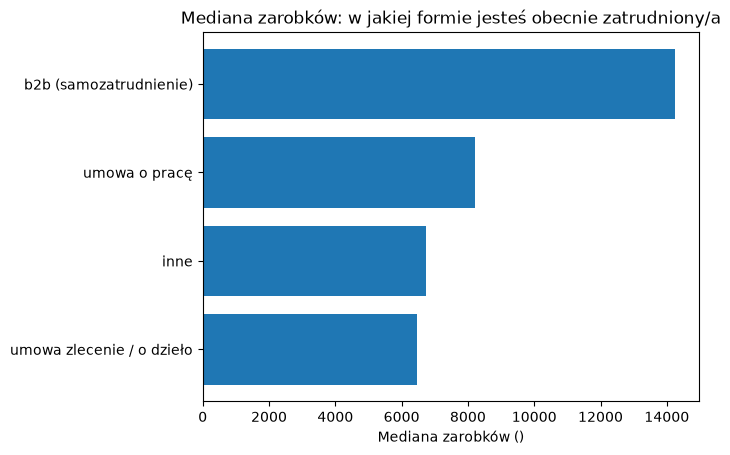

                                median  count
poziom stanowiska (seniority)                
junior                          6500.0     39
mid / regular                   8000.0    151
stażysta / praktykant           9700.0      2
lead / expert                  10900.0     17
senior                         12400.0     44
manager / team leader          13500.0     13


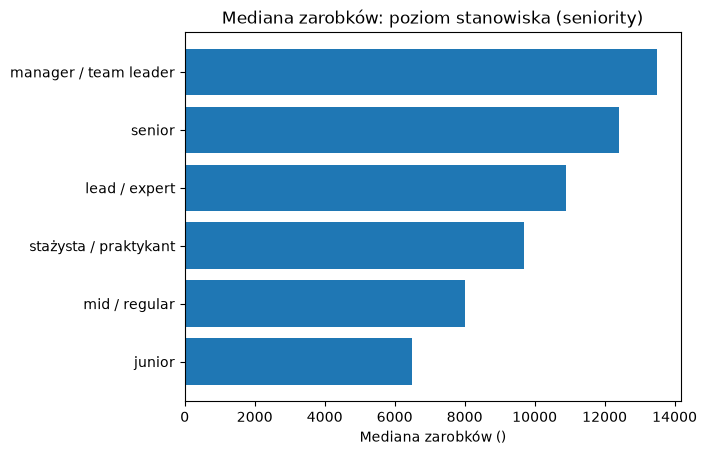

                                       median  count
stanowisko                                          
data analyst                           7700.0    149
business analyst                       8500.0     19
analytics engineer                     9100.0      3
data scientist                         9500.0     33
data engineer                         10000.0     31
business intelligence (bi) developer  11300.0     25
ml/ai engineer                        11500.0      7


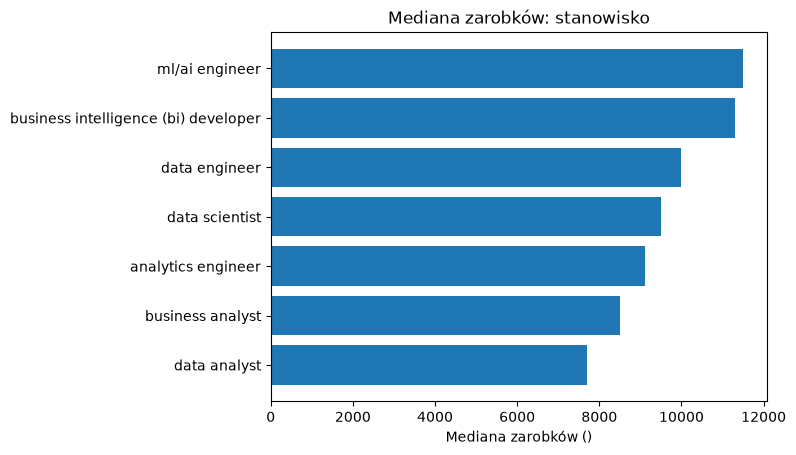

                    median  count
lata doświadczenia               
do 2 lat            6500.0     16
3–5 lat             7300.0     75
ponad 15 lat        8750.0     28
6–10 lat            9400.0     89
11-15 lat           9500.0     59


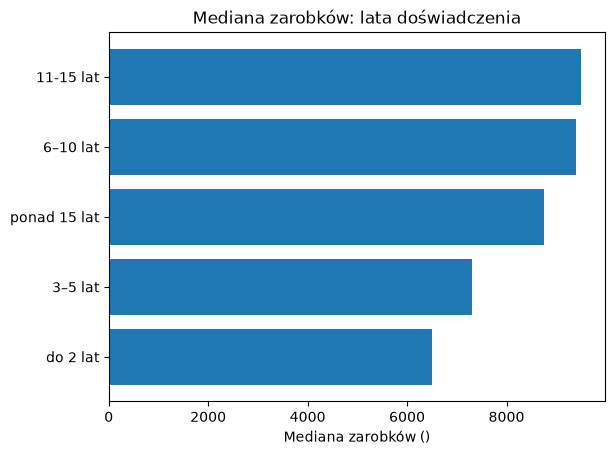

                                       median  count
wielkość firmy, w której pracujesz                  
mała firma (10-50 pracowników)         6800.0     15
bardzo mała firma (< 10 pracowników)   7800.0      3
średnia firma (50–500 pracowników)     8000.0     69
duża firma (powyżej 500 pracowników)   8950.0    178
freelancer                            11000.0      1


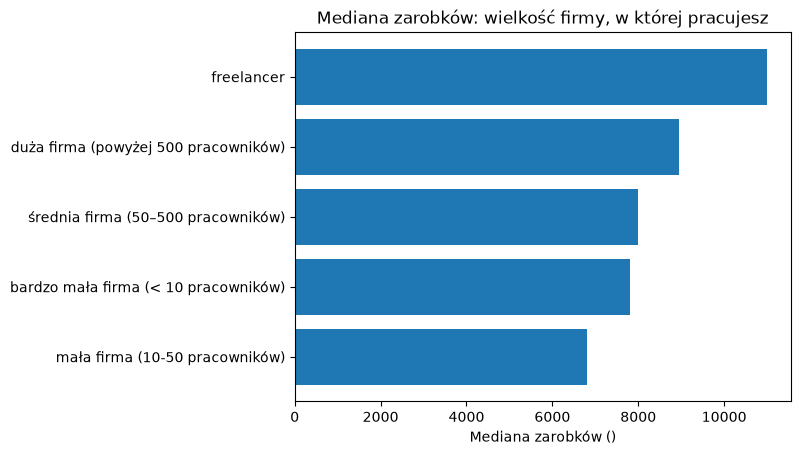

                                           median  count
jaki kapitał ma firma, w której pracujesz               
inne/trudno powiedzieć                     7500.0      9
polska                                     7600.0    133
międzynarodowa                             9100.0    124


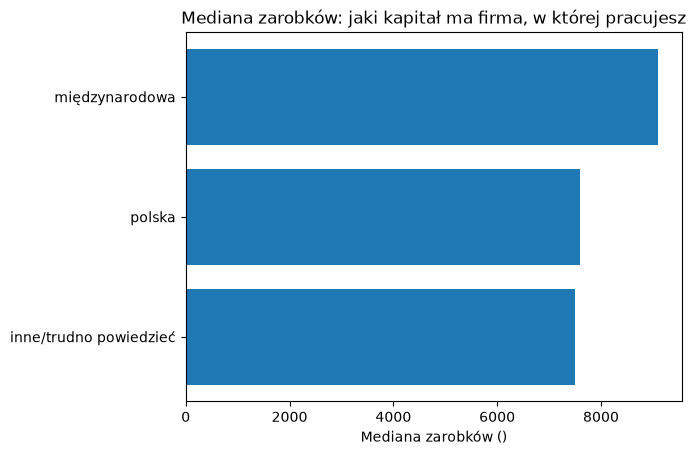

                                             median  count
miejsce zamieszkania                                      
małe miasto (poniżej 100 tys. mieszkańców)   7000.0     28
średnie miasto (100–500 tys. mieszkańców)    8000.0     35
duże miasto (powyżej 500 tys. mieszkańców)   8500.0    178
wieś / obszar wiejski                       10000.0     26


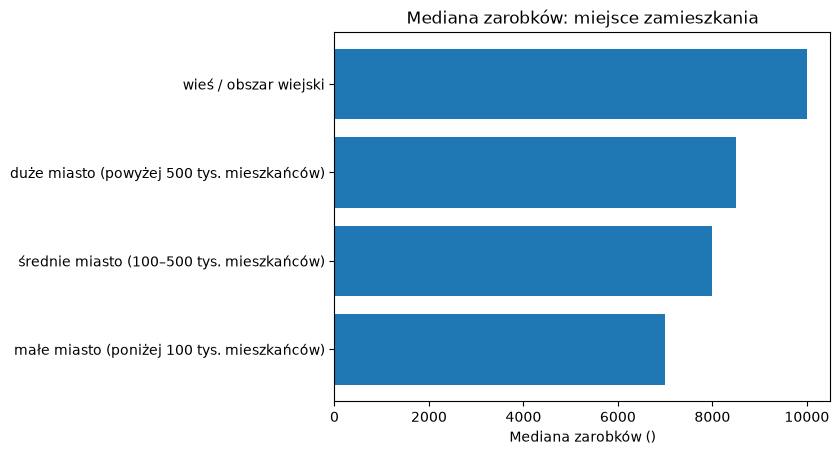

           median  count
płeć                    
kobieta    8500.0    149
mężczyzna  8500.0    118


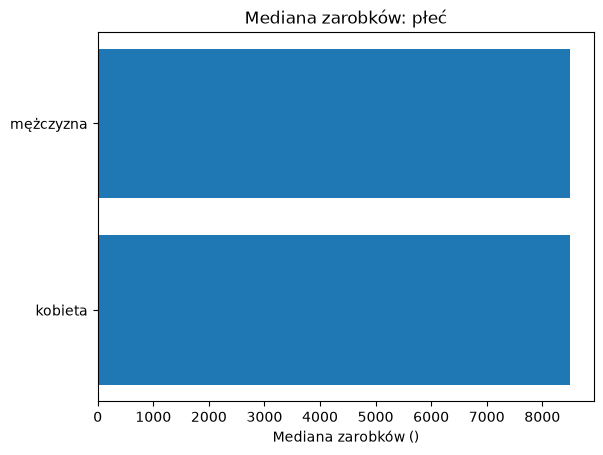

                                                    median  count
kierunek wykształcenia                                           
Przyrodnicze (np. biologia, chemia, geografia)      7300.0      9
Inne techniczne (np. inżynieria, automatyka, fi...  7500.0     57
Matematyczne / statystyczne                         8250.0     50
Inne                                                8400.0      4
Informatyczne                                       8600.0     57
Humanistyczne lub społeczne (np. psychologia, s...  8750.0     32
Ekonomiczne / finansowe                             9400.0     49


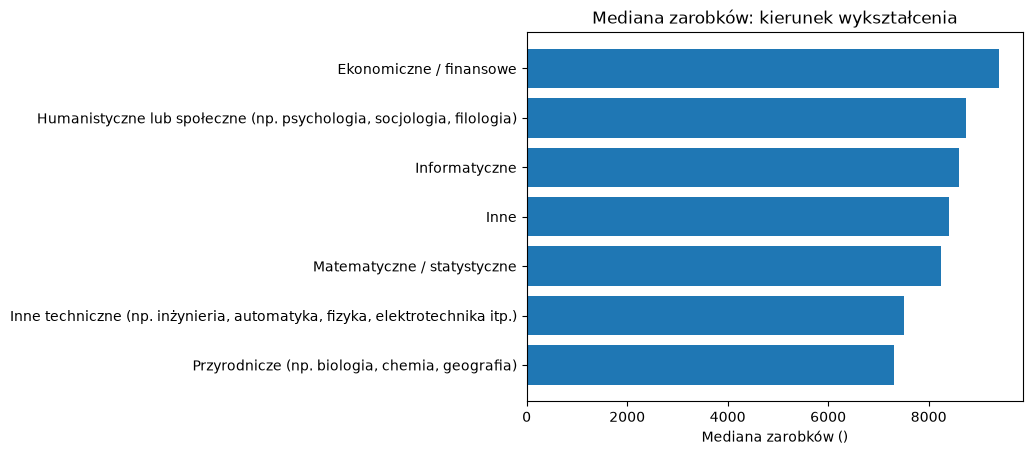

In [18]:
# Czynniki, które mogą wpływać na zarobki
czynniki = [
    'w jakiej formie jesteś obecnie zatrudniony/a',
    'poziom stanowiska (seniority)',
    'stanowisko',
    'lata doświadczenia',
    'wielkość firmy, w której pracujesz',
    'jaki kapitał ma firma, w której pracujesz',
    'miejsce zamieszkania',
    'płeć',
    'kierunek wykształcenia'
]

for czynnik in czynniki:
    porownaj_zarobki(czynnik)

**Wnioski do podpunktu A.**

- **Forma zatrudnienia:** mediana na B2B (14 250 , 32 osoby) jest znacznie wyższa niż na umowie o pracę (8 200 , 227 osób). Pozostałe formy są zbyt mało liczne na wnioski.
- **Seniority:** mediana rośnie od juniora (6 500 ) przez mida (8 000 ) do seniora (12 400 ) i managera (13 500 , 13 osób). Wynik stażystów opiera się tylko na 2 osobach.
- **Stanowisko:** wśród liczniejszych grup najwyższą medianę ma BI developer (11 300 ), a najniższą data analyst (7 700 ). Wynik ml/ai engineera (11 500 ) opiera się tylko na 7 osobach.
- **Doświadczenie:** mediana rośnie z 6 500 (do 2 lat) do ok. 9 400–9 500 (6–15 lat). Przy ponad 15 latach jest niższa (8 750, 28 osób), ale ta grupa jest mała, a różnica niepewna, więc nie oznacza to spadku zarobków wraz z doświadczeniem.
- **Firma:** wyższe mediany występują w dużych firmach (8 950 ) i firmach międzynarodowych (9 100 , wobec 7 600  w polskich).
- **Miejsce zamieszkania:** najwyższa mediana występuje na wsi (10 000 , 26 osób), co może zależeć od innych czynników, np. stanowiska lub pracy zdalnej.
- **Płeć:** mediana jest taka sama dla kobiet i mężczyzn (8 500 ).
- **Kierunek:** najwyższą medianę mają absolwenci kierunków ekonomicznych (9 400 , 49 osób), a wśród liczniejszych grup najniższą kierunki inne techniczne (7 500 , 57 osób). Ten wynik też może zależeć od innych czynników.

Porównania mają charakter opisowy: pokazują różnice w zarobkach, ale nie dowodzą ich przyczyny.

### B. Stanowisko a seniority: zarobki na poszczególnych poziomach.

In [19]:
seniority = 'poziom stanowiska (seniority)'

for poziom in ['junior', 'mid / regular', 'senior']:
    grupa = df[df[seniority] == poziom]
    print(f"\n{poziom}: liczba osób z podanymi zarobkami: {grupa['zarobki'].count()}, mediana zarobków: {grupa['zarobki'].median():.0f} ")
    display(grupa.groupby('stanowisko')['zarobki'].agg(['median', 'count']).sort_values('median', ascending=False))


junior: liczba osób z podanymi zarobkami: 39, mediana zarobków: 6500 


,median,count
stanowisko,,
data engineer,8250.0,8
data scientist,7200.0,3
ml/ai engineer,7100.0,1
business intelligence (bi) developer,6700.0,5
data analyst,6000.0,20
business analyst,5875.0,2



mid / regular: liczba osób z podanymi zarobkami: 151, mediana zarobków: 8000 


,median,count
stanowisko,,
data engineer,9200.0,19
analytics engineer,9100.0,3
business intelligence (bi) developer,9000.0,5
ml/ai engineer,9000.0,3
data scientist,8500.0,17
data analyst,7500.0,92
business analyst,7100.0,12



senior: liczba osób z podanymi zarobkami: 44, mediana zarobków: 12400 


,median,count
stanowisko,,
ml/ai engineer,17000.0,3
data engineer,16333.0,3
data scientist,16000.0,9
business intelligence (bi) developer,12250.0,10
business analyst,9300.0,3
data analyst,8950.0,16
analytics engineer,NaN,0


**Wnioski do podpunktu B.**

- **Data engineer** ma medianę wyższą od mediany wszystkich osób na każdym poziomie: junior 8 250 (wobec 6 500, 8 osób), mid 9 200 (wobec 8 000, 19 osób) i senior 16 333 (wobec 12 400, tylko 3 osoby).
- **Data scientist** również przewyższa medianę na każdym poziomie: mid 8 500 (17 osób) i senior 16 000 (9 osób). Wynik dla juniorów opiera się tylko na 3 osobach.
- **BI developer** wypada różnie: powyżej mediany na poziomie mid (9 000, 5 osób), a nieco poniżej na poziomie senior (12 250, 10 osób).
- **Data analyst** ma medianę niższą od mediany wszystkich osób na każdym poziomie: junior 6 000 (20 osób), mid 7 500 (92 osoby) i senior 8 950 (16 osób). **Business analyst** również jest poniżej mediany na każdym poziomie, ale to mniejsza grupa.
- **Liczebność a łatwość wejścia:** data analyst to najliczniejsza grupa i ma najwięcej juniorów i stażystów w liczbach bezwzględnych (23), ale stanowią oni tylko 14% tej grupy. Sama liczebność nie pozwala więc stwierdzić, że na to stanowisko najłatwiej się dostać. Łatwość wejścia zostanie oceniona w kolejnym punkcie.
- **Wiarygodność wyników:** najpewniejsze są wyniki dla poziomu mid, ponieważ jest tam najwięcej osób z podanymi zarobkami (151, wobec 39 juniorów i 44 seniorów), np. 92 data analystów, 19 data engineerów i 17 data scientistów. Także na tym poziomie część grup jest mała, np. BI developer (5 osób) i ml/ai engineer (3 osoby). Większość grup juniorów i seniorów liczy mniej niż 20 osób, dlatego te wyniki są orientacyjne.

### C. Stanowisko a forma zatrudnienia: umowa o pracę i B2B.

In [20]:
forma = 'w jakiej formie jesteś obecnie zatrudniony/a'

for rodzaj in ['umowa o pracę', 'b2b (samozatrudnienie)']:
    grupa = df[df[forma] == rodzaj]
    print(f"\n{rodzaj}: liczba osób z podanymi zarobkami: {grupa['zarobki'].count()}, mediana zarobków: {grupa['zarobki'].median():.0f} ")
    display(grupa.groupby('stanowisko')['zarobki'].agg(['median', 'count']).sort_values('median', ascending=False))


umowa o pracę: liczba osób z podanymi zarobkami: 227, mediana zarobków: 8200 


,median,count
stanowisko,,
analytics engineer,12300.0,2
ml/ai engineer,10250.0,6
data scientist,9500.0,28
data engineer,9100.0,20
business intelligence (bi) developer,9000.0,17
business analyst,8000.0,17
data analyst,7600.0,137



b2b (samozatrudnienie): liczba osób z podanymi zarobkami: 32, mediana zarobków: 14250 


,median,count
stanowisko,,
data scientist,22000.0,3
business analyst,16500.0,2
ml/ai engineer,16000.0,1
business intelligence (bi) developer,14750.0,8
data engineer,12650.0,10
data analyst,11000.0,7
analytics engineer,9100.0,1


**Wnioski do podpunktu C.**

- **Umowa o pracę:** wśród grup liczących co najmniej 17 osób najwyższą medianę ma data scientist (9 500, 28 osób), a za nim data engineer (9 100, 20 osób) i BI developer (9 000, 17 osób). Najniższą medianę ma data analyst (7 600, 137 osób).
- **B2B:** na stanowiskach z co najmniej 7 osobami mediana jest wyraźnie wyższa niż na umowie o pracę: BI developer 14 750 (8 osób), data engineer 12 650 (10 osób) i data analyst 11 000 (7 osób). Grupy są jednak małe, więc wyniki są orientacyjne.
- **Wpływ na ranking:** BI developer ma ogólną medianę 11 300, ale na umowie o pracę już 9 000. Jego wysoka pozycja w ogólnym porównaniu może więc częściowo wynikać z udziału osób na B2B.
- **Podobne osoby:** wśród midów na umowie o pracę data engineer ma medianę 9 100 (12 osób), data scientist 8 750 (16 osób), a data analyst 7 400 (87 osób).

### Podsumowanie punktu 4

**Co wpływa na wynik porównania?**
Zarobki wyraźnie różnią się w zależności od doświadczenia (seniority) i formy zatrudnienia. Seniorzy zarabiają więcej niż juniorzy, a osoby na B2B więcej niż osoby na umowie o pracę. Dlatego wynik stanowiska zależy też od tego, kto na nim pracuje.

**Przykład: BI developer**
W tabeli ogólnej (punkt A) BI developer wypada bardzo dobrze, z medianą 11 300. Gdy jednak porówna się juniorów z juniorami, midów z midami i seniorów z seniorami (punkt B), BI developer nigdzie nie zarabia najwięcej. Przy umowie o pracę (punkt C) zarabia mniej więcej tyle samo co data engineer i data scientist.

Wynika to ze składu grupy. Wśród BI developerów seniorzy to 10 z 25 osób, a wśród data engineerów tylko 3 z 31. Seniorzy podnoszą medianę całej grupy BI.

**Napotkany problem: analizować dane w całości czy po podziale?**
Bez podziału grupy są duże (np. 149 data analystów), ale porównuje się osoby o różnym doświadczeniu, jak w przykładzie z BI developerem. Po podziale porównuje się podobne osoby, ale wiele grup staje się bardzo małych:

- wśród seniorów jest tylko 3 data engineerów i 3 ML engineerów,
- wśród juniorów jest 5 BI developerów i 2 business analystów,
- na B2B są łącznie 32 osoby, w tym tylko 2 business analystów.

W tak małej grupie jedna osoba może całkowicie zmienić wynik.

**Rozwiązanie:** wnioski oparto na tym, co powtarza się na wszystkich poziomach seniority, a nie na pojedynczych liczbach.

**Co powtarza się na wszystkich poziomach seniority?**
Mediana każdego stanowiska została porównana z medianą wszystkich osób na tym samym poziomie (junior, mid, senior).

- **Data engineer i data scientist** zawsze wypadają powyżej mediany. To najpewniejszy wynik.
- **Data analyst** zawsze wypada poniżej mediany. To największa grupa w badaniu, więc wynik jest wiarygodny.
- **Business analyst** również zawsze wypada poniżej, ale grupy są małe.
- **ML engineer** zawsze wypada powyżej, ale to tylko 7 osób, więc wynik jest orientacyjny.
- **BI developer** nie ma stałego wzoru: jako junior i mid wypada powyżej, a jako senior mniej więcej na poziomie mediany.
- **Analytics engineer** występuje tylko na poziomie mid, więc nie da się go ocenić.

**Forma zatrudnienia:** przy umowie o pracę wyniki są podobne. Na B2B grupy są zbyt małe, żeby oceniać poszczególne stanowiska. Widać jedynie, że osoby na B2B zarabiają wyraźnie więcej niezależnie od stanowiska.

## 5. Wskaźniki progu wejścia

**Cel:** sprawdzenie, jak łatwo wejść na poszczególne stanowiska.

W ankiecie nie ma pytania o trudność wejścia do zawodu, dlatego oceniono ją pośrednio, za pomocą sześciu wskaźników.

**Przebieg:**

- **A.** Dla każdej osoby przygotowano kolumny pomocnicze, np. czy przyszła spoza branży i czy ma dyplom.
- **B.** Dla każdego stanowiska policzono odsetki i mediany tych wskaźników i zebrano je w jednej tabeli.

Wskaźniki wzięte pod uwagę:

| Wskaźnik | Co oznacza | Łatwiejsze wejście, gdy wartość jest |
|---|---|---|
| % osób spoza branży | osoby, które przyszły z innej branży lub to ich pierwsza praca | wyższa |
| % juniorów i stażystów | osoby na początku kariery | wyższa |
| % osób bez dyplomu | osoby bez licencjatu, inżyniera, magistra ani doktoratu | wyższa |
| % osób po kierunku nietechnicznym | osoby po kierunku innym niż informatyka, inne techniczne, matematyka i statystyka | wyższa |
| Programowanie | mediana udziału programowania w pracy (skala 1–10) | niższa |
| Liczba narzędzi | mediana liczby narzędzi używanych w pracy | niższa |

### A. Kolumny pomocnicze.

In [ ]:
# dopisujemy nowe kolumny do istniejącego df: spoza_branzy, junior_lub_staz, bez_dyplomu, kierunek_nietechniczny i liczba_narzedzi
przed = 'czy przed objęciem obecnego stanowiska pracowałeś/aś już w branży it lub analitycznej'
df['spoza_branzy'] = df[przed].str.startswith('nie') 
# sprawdza pierwsze litery każdej odpowiedzi; „nie” to True, w przeciwnym razie False

df['junior_lub_staz'] = df['poziom stanowiska (seniority)'].isin(['junior', 'stażysta / praktykant'])

dyplomy = ['wykształcenie__licencjat', 'wykształcenie__inżynier', 'wykształcenie__magister', 'wykształcenie__doktorat']
df['bez_dyplomu'] = df[dyplomy].sum(axis=1) == 0
# sumuje dyplomy w wierszu; wynik 0 oznacza, że osoba nie ma żadnego dyplomu

kierunek = 'kierunek wykształcenia'
techniczne = ['Informatyczne',
              'Inne techniczne (np. inżynieria, automatyka, fizyka, elektrotechnika itp.)',
              'Matematyczne / statystyczne']
df['kierunek_nietechniczny'] = (~df[kierunek].isin(techniczne)).where(df[kierunek].notna())
# ~ odwraca warunek, czyli „nie jest na liście kierunków technicznych”
# .where(df[kierunek].notna()) zostawia puste pole u 9 osób, które nie podały kierunku; bez tego zostałyby policzone jako osoby po kierunku nietechnicznym

narzedzia = [kol for kol in df.columns if kol.startswith('narzędzia | ')]
df['liczba_narzedzi'] = df[narzedzia].sum(axis=1)
# narzedzia to lista wszystkich 23 kolumn zaczynających się od narzędzia | ; każda ma 0 albo 1, więc ich suma to liczba narzędzi danej osoby

### B. Tabela wskaźników.

Dla każdego stanowiska policzono sześć wskaźników progu wejścia i zebrano je w jednej tabeli.

W `.agg()` użyto zapisu `nazwa=('kolumna', 'funkcja')`, który pozwala dla każdej kolumny wybrać inną funkcję (np. `mean` lub `median`) i od razu nadać wynikowi krótką nazwę. Na przykład `programowanie=('jaki procent twojej pracy stanowi programowanie', 'median')` liczy medianę z kolumny o długiej nazwie i zapisuje wynik jako `programowanie`.

In [ ]:
wskazniki = df.groupby('stanowisko').agg(
    liczba_osob=('id', 'count'),
    spoza_branzy=('spoza_branzy', 'mean'),
    junior_lub_staz=('junior_lub_staz', 'mean'),
    bez_dyplomu=('bez_dyplomu', 'mean'),
    kierunek_nietechniczny=('kierunek_nietechniczny', 'mean'),
    programowanie=('jaki procent twojej pracy stanowi programowanie', 'median'),
    narzedzia=('liczba_narzedzi', 'median'),
)

procenty = ['spoza_branzy', 'junior_lub_staz', 'bez_dyplomu', 'kierunek_nietechniczny']
wskazniki[procenty] = (wskazniki[procenty] * 100).round(0)

wskazniki.sort_values('liczba_osob', ascending=False)

,liczba_osob,spoza_branzy,junior_lub_staz,bez_dyplomu,kierunek_nietechniczny,programowanie,narzedzia
stanowisko,,,,,,,
data analyst,162,46.0,14.0,9.0,35.897436,5.0,3.5
data scientist,39,26.0,13.0,3.0,28.947368,7.0,5.0
data engineer,33,36.0,27.0,21.0,33.333333,7.0,4.0
business intelligence (bi) developer,26,35.0,23.0,12.0,40.0,6.0,4.0
business analyst,20,45.0,10.0,5.0,57.894737,4.0,3.0
ml/ai engineer,13,15.0,8.0,8.0,7.692308,7.0,7.0
analytics engineer,4,0.0,0.0,0.0,25.0,7.5,6.5


**Wnioski**

- **Data analyst i business analyst** wyglądają na najłatwiejsze do wejścia. Spoza branży przyszło odpowiednio 46% i 45% osób, a kierunek nietechniczny ukończyło 36% i 58%. Praca wymaga najmniej programowania (mediana 5 i 4 w skali 1–10) i najmniejszej liczby narzędzi (mediana 3,5 i 3). Juniorów i stażystów jest jednak stosunkowo mało (14% i 10%).
- **Data engineer i BI developer** są pośrodku. Praca wymaga więcej programowania (mediana 7 i 6), ale te stanowiska mają najwięcej juniorów i stażystów (27% i 23%), a wśród data engineerów najwięcej osób bez dyplomu (21%). Wejście jest więc trudniejsze technicznie, ale dość otwarte.
- **Data scientist i ML/AI engineer** wyglądają na najtrudniejsze. Spoza branży przyszło tylko 26% i 15% osób, dyplom ma 97% i 92%, a juniorów i stażystów jest 13% i 8%. Praca wymaga dużo programowania (mediana 7) i najwięcej narzędzi (mediana 5 i 7). Wśród ML/AI engineerów kierunek nietechniczny ukończyło tylko 8% osób.
- **Analytics engineer** to tylko 4 osoby, więc nie da się go ocenić.

**Ograniczenia:** wskaźniki opisują próg wejścia tylko pośrednio. Ankietę wypełniły wyłącznie osoby, które już pracują w branży, dlatego nie wiadomo, ile osób bezskutecznie próbowało zdobyć pracę na danym stanowisku.

## 6. Indeks progu wejścia

**Cel:** połączenie sześciu wskaźników w jedną liczbę, co ułatwi porównanie stanowisk. Wskaźniki zostały omówione w punkcie 5.

**Problem:** wskaźniki są mierzone w różnych skalach. Cztery wskaźniki wyrażone są w procentach (od 0 do 100), 
programowanie jest oceniane w skali od 1 do 10, a liczba narzędzi wynosi od 3 do 7. Dlatego nie można ich do siebie dodać.

**Rozwiązanie:** każdy wskaźnik zamienia się na skalę od 0 do 1. Stanowisko z najtrudniejszym wejściem dostaje 0, a stanowisko z najłatwiejszym 1. 
Potem z sześciu wartości liczy się średnią i to jest indeks.

### A. Wybór stanowisk.

Do indeksu wybrano tylko stanowiska, na których pracuje co najmniej 10 osób. Pominięto w ten sposób analytics engineera (4 osoby). Jego wyniki opierają się na zbyt małej grupie i mogłyby zniekształcić skalę w kroku B, bo w trzech wskaźnikach ma 0%.

Wybrane stanowiska zapisano w nowej tabeli `indeks`. Tabela `wskazniki` z punktu 5 pozostała bez zmian.

In [24]:
indeks = wskazniki[wskazniki['liczba_osob'] >= 10].copy()
# tworzymy zmienną indeks, która zawiera tylko stanowiska z co najmniej 10 osobami w próbie
# .copy() tworzy kopię df

### B. Ujednolicenie skali.

Każdy wskaźnik przeliczono na skalę od 0 do 1: najtrudniejsze wejście = 0, najłatwiejsze = 1.

In [ ]:
kolumny = ['spoza_branzy', 'junior_lub_staz', 'bez_dyplomu', 'kierunek_nietechniczny', 'programowanie', 'narzedzia']

skala = (indeks[kolumny] - indeks[kolumny].min()) / (indeks[kolumny].max() - indeks[kolumny].min())
# przeskalowuje wartości w kolumnach do przedziału 0-1; min = 0, max = 1
# jak daleko dane stanowisko jest od najniższej wartości w porównaniu z całym zakresem?
# najniższa wartość daje 0, najwyższa 1, a reszta wypada pomiędzy. 
# np. dla „spoza branży” ML/AI engineer (15%) dostaje 0, a data analyst (46%) dostaje 1

skala['programowanie'] = 1 - skala['programowanie']
skala['narzedzia'] = 1 - skala['narzedzia']
# odwraca kierunek dla programowania i narzędzi. 
# Przy nich wyższa wartość oznacza trudniejsze wejście, a w indeksie wyższa liczba ma znaczyć łatwiejsze wejście.

### C. Obliczenie indeksu.

Dla każdego stanowiska policzono średnią z sześciu wskaźników przeliczonych w kroku B. Im wyższy indeks, tym łatwiej wejść na stanowisko.

In [26]:
indeks['indeks'] = skala.mean(axis=1).round(2)
# średnia ze wszystkich 6 wskaźników daje jeden wskaźnik, który pokazuje, jak łatwo jest wejść na dane stanowisko.

indeks[['liczba_osob', 'indeks']].sort_values('indeks', ascending=False)
# tabela z liczbą osób i indeksem, posortowana od najwyższego indeksu do najniższego

,liczba_osob,indeks
stanowisko,,
business analyst,20,0.7
data engineer,33,0.66
data analyst,162,0.63
business intelligence (bi) developer,26,0.61
data scientist,39,0.26
ml/ai engineer,13,0.05


**Wnioski**

- **Stanowiska dzielą się na dwie wyraźne grupy.** Business analyst (0.70), data engineer (0.66), data analyst (0.63) i BI developer (0.61) mają podobny, wysoki indeks. Data scientist (0.26) i ML/AI engineer (0.05) wypadają wyraźnie gorzej.
- **W pierwszej grupie różnice są małe**, dlatego kolejność tych czterech stanowisk nie jest pewna. Wszystkie można uznać za stosunkowo łatwe do wejścia.
- **Data engineer** znalazł się w pierwszej grupie mimo dużej ilości programowania. Duży udział juniorów (27%) i osób bez dyplomu (21%) sprawia, że to stanowisko jest dość otwarte dla nowych osób.
- **Data scientist i ML/AI engineer** mają najwyższy próg wejścia: mało osób spoza branży, prawie wszyscy z dyplomem, dużo programowania i narzędzi.

**Ograniczenia:** każdy wskaźnik ma w indeksie taką samą wagę. Przy innym podejściu, np. gdyby programowanie liczyło się bardziej, kolejność w pierwszej grupie mogłaby się zmienić.

## 7. Próg wejścia a zarobki.

**Cel:** zestawienie indeksu progu wejścia z zarobkami, żeby sprawdzić, które stanowisko łączy łatwe wejście z dobrymi zarobkami. Wyniki zostaną przedstawione w formie tabeli i wykresu punktowego.

**Przebieg:**

- **A.** Dla każdej osoby policzono zarobki względne: jej zarobki podzielone przez medianę zarobków na jej poziomie seniority. Wartość powyżej 1 oznacza zarobki wyższe niż u typowej osoby z podobnym doświadczeniem.
- **B.** Dla każdego stanowiska policzono medianę zarobków względnych i połączono ją z indeksem progu wejścia w jednej tabeli.
- **C.** Wyniki pokazano na wykresie punktowym.

### A. Zarobki względne.

**Jak liczone są zarobki względne?**

Jak to działa krok po kroku:

1. Każda osoba ma swoje zarobki.
2. Każdą dzieli się przez medianę jej poziomu, np. u juniorów to zawsze 6 500, u midów 8 000 etc.
3. Zarobki względne to zarobek indywidualny podzielony przez medianę poziomu

In [ ]:
seniority = 'poziom stanowiska (seniority)'

df['mediana_poziomu'] = df.groupby(seniority)['zarobki'].transform('median')
# transform('median') oblicza medianę zarobków dla każdego poziomu stanowiska i przypisuje ją do każdej osoby w df

df['zarobki_wzgledne'] = df['zarobki'] / df['mediana_poziomu']
# zarobki_wzgledne to stosunek zarobków danej osoby do mediany zarobków dla jej poziomu stanowiska

In [32]:
df[['stanowisko', seniority, 'zarobki', 'mediana_poziomu', 'zarobki_wzgledne']].head(10).round(2)
# wyświetla pierwsze 10 wierszy z kolumnami stanowisko, poziom stanowiska, zarobki, mediana poziomu i zarobki względne          

,stanowisko,poziom stanowiska (seniority),zarobki,mediana_poziomu,zarobki_wzgledne
0,data analyst,mid / regular,11000.0,8000.0,1.38
1,data analyst,mid / regular,7500.0,8000.0,0.94
2,data engineer,junior,10000.0,6500.0,1.54
3,data analyst,manager / team leader,10000.0,13500.0,0.74
4,business analyst,mid / regular,9800.0,8000.0,1.23
5,data analyst,mid / regular,7700.0,8000.0,0.96
6,data scientist,mid / regular,13500.0,8000.0,1.69
7,data scientist,NaN,5000.0,NaN,NaN
8,data engineer,mid / regular,9000.0,8000.0,1.12
9,data engineer,mid / regular,12000.0,8000.0,1.50


### B. Zestawienie w tabeli.

Dla każdego stanowiska policzono medianę zarobków, medianę zarobków względnych i liczbę osób, które podały zarobki. Wyniki połączono z indeksem progu wejścia w jednej tabeli `zestawienie`.

In [ ]:
# Wykresy zależności indeksu od mediany zarobków i mediany zarobków względnych
zarobki_stanowisk = df.groupby('stanowisko').agg(
    mediana_zarobkow=('zarobki', 'median'),
    zarobki_wzgledne=('zarobki_wzgledne', 'median'),
    osoby_z_zarobkami=('zarobki', 'count'),
)

zestawienie = indeks[['indeks']].join(zarobki_stanowisk)
zestawienie['zarobki_wzgledne'] = zestawienie['zarobki_wzgledne'].round(2)
# .join() łączy dwie tabele po nazwach stanowisk. Tabela indeks nie ma analytics engineera, więc w zestawieniu też go nie będzie.

zestawienie.sort_values('indeks', ascending=False)

,indeks,mediana_zarobkow,zarobki_wzgledne,osoby_z_zarobkami
stanowisko,,,,
business analyst,0.7,8500.0,0.92,19
data engineer,0.66,10000.0,1.23,31
data analyst,0.63,7700.0,0.91,149
business intelligence (bi) developer,0.61,11300.0,1.01,25
data scientist,0.26,9500.0,1.16,33
ml/ai engineer,0.05,11500.0,1.29,7


**Wnioski**

- **Data engineer** łączy łatwe wejście (indeks 0.66) z wysokimi zarobkami (1.23).
- **Business analyst i data analyst** mają łatwe wejście (0.70 i 0.63), ale niższe zarobki (0.92 i 0.91).
- **BI developer** ma łatwe wejście (0.61) i przeciętne zarobki (1.01).
- **Data scientist i ML/AI engineer** zarabiają więcej (1.16 i 1.29), ale wejście jest najtrudniejsze (0.26 i 0.05).

### C. Wykres punktowy.

Każde stanowisko pokazano jako punkt. Oś pozioma to indeks progu wejścia, a oś pionowa to zarobki względne. Przerywana linia oznacza zarobki typowej osoby na tym samym poziomie seniority. Najkorzystniejsze stanowiska znajdują się w prawym górnym rogu: łatwe wejście i zarobki powyżej linii.

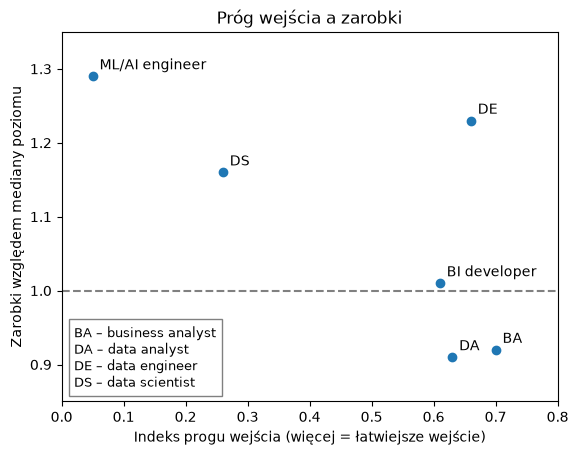

In [35]:
krotkie_nazwy = {
    'business analyst': 'BA',
    'data analyst': 'DA',
    'business intelligence (bi) developer': 'BI developer',
    'data engineer': 'DE',
    'data scientist': 'DS',
    'ml/ai engineer': 'ML/AI engineer',
}

plt.scatter(zestawienie['indeks'], zestawienie['zarobki_wzgledne'])
# rysuje jeden punkt dla każdego stanowiska

for stanowisko, wiersz in zestawienie.iterrows():
    plt.annotate(krotkie_nazwy[stanowisko],
                 (wiersz['indeks'], wiersz['zarobki_wzgledne']),
                 xytext=(5, 5), textcoords='offset points')
# pętla .iterrows() przechodzi po wierszach tabeli i przy każdym punkcie dopisuje nazwę stanowiska.

plt.axhline(1, color='gray', linestyle='--')
# rysuje poziomą linię przerywaną na wysokości 1, która pokazuje medianę zarobków dla danego poziomu stanowiska

plt.xlim(0, 0.8)
plt.ylim(0.85, 1.35)
plt.title('Próg wejścia a zarobki')
plt.xlabel('Indeks progu wejścia (więcej = łatwiejsze wejście)')
plt.ylabel('Zarobki względem mediany poziomu')
objasnienie = ('BA – business analyst\n'
               'DA – data analyst\n'
               'DE – data engineer\n'
               'DS – data scientist')

plt.text(0.02, 0.87, objasnienie, fontsize=9,
         bbox=dict(facecolor='white', edgecolor='gray'))
plt.show()

**Wnioski**

- W prawym górnym rogu, czyli przy łatwym wejściu i zarobkach powyżej linii, znajduje się tylko **data engineer**.
- **Business analyst, data analyst i BI developer** mają łatwe wejście, ale zarobki na poziomie linii lub poniżej.
- **Data scientist i ML/AI engineer** są w lewym górnym rogu: zarabiają więcej, ale wejście jest najtrudniejsze.
- Wykres pokazuje, że zwykle trzeba wybierać między łatwym wejściem a wyższymi zarobkami. Wyjątkiem jest data engineer.

### Podsumowanie punktu 7

**Główny wynik:** spośród badanych stanowisk tylko **data engineer** łączy stosunkowo łatwe wejście (indeks 0.66) z zarobkami wyraźnie wyższymi niż u osób z podobnym doświadczeniem (o 23% więcej).

**Pozostałe stanowiska:**

- **Business analyst, data analyst i BI developer** mają łatwe wejście, ale ich zarobki są przeciętne lub niższe niż u osób na tym samym poziomie.
- **Data scientist i ML/AI engineer** dają wyższe zarobki, ale wejście na nie jest najtrudniejsze.

**Ograniczenia:**

- Zarobki względne nie uwzględniają formy zatrudnienia, więc osoby na B2B podnoszą wynik swojego stanowiska.
- Wynik ML/AI engineera opiera się tylko na 7 osobach.
- Indeks progu wejścia zakłada, że wszystkie wskaźniki są tak samo ważne.
- Wyniki pokazują związek, a nie przyczynę. Wybór stanowiska nie gwarantuje wyższych zarobków.

## 8. Sprawdzenie stabilności wyniku

**Cel:** sprawdzenie, czy data engineer pozostaje najlepszym wyborem, gdy w analizie zostaną podjęte inne decyzje.

W poprzednich punktach przyjęto kilka założeń:

- wszystkie wskaźniki w indeksie progu wejścia mają taką samą wagę,
- zarobki są liczone względem mediany poziomu seniority,
- osoby na B2B są liczone razem z osobami na umowie o pracę,

W tym punkcie sprawdzono, czy data engineer nadal wygrywa, gdy któreś z tych założeń zostanie zmienione. Jeśli wynik się nie zmienia, można uznać go za stabilny.

**Reguła wyboru zwycięzcy:** spośród stanowisk z indeksem progu wejścia co najmniej 0.5 wygrywa to, które ma najwyższe zarobki.

**Sprawdzone warianty:**

| Wariant | Jak było dotychczas | Co zmieniono |
|---|---|---|
| A | zarobki względne (zarobki podzielone przez medianę poziomu) | zwykła mediana zarobków |
| B | wszystkie formy zatrudnienia razem | tylko osoby na umowie o pracę |
| C | indeks z sześciu wskaźników o równej wadze | indeks z pięciu wskaźników, po kolei bez każdego z nich |

**Funkcja wybierająca zwycięzcę:**

In [36]:
def zwyciezca(indeksy, zarobki):
    latwe = indeksy[indeksy >= 0.5].index
    return zarobki[latwe].idxmax()

zwyciezca(zestawienie['indeks'], zestawienie['zarobki_wzgledne'])

'data engineer'

**Co robi ta funkcja:**

- `latwe = ...` zostawia tylko stanowiska z łatwym wejściem, czyli z indeksem co najmniej 0.5.
- `return zarobki[latwe]...` spośród nich zwraca nazwę stanowiska z najwyższymi zarobkami.

### Wariant A. Zwykła mediana.

In [37]:
zwyciezca(zestawienie['indeks'], zestawienie['mediana_zarobkow'])

'business intelligence (bi) developer'

### Wariant B. Umowa o pracę.

Kod jest taki sam jak w punkcie 7A, tylko liczony wyłącznie dla osób na umowie o pracę.

In [38]:
forma = 'w jakiej formie jesteś obecnie zatrudniony/a'

uop = df[df[forma] == 'umowa o pracę'].copy()
uop['zarobki_wzgledne_uop'] = uop['zarobki'] / uop.groupby(seniority)['zarobki'].transform('median')
zarobki_uop = uop.groupby('stanowisko')['zarobki_wzgledne_uop'].median()

zwyciezca(zestawienie['indeks'], zarobki_uop)

'data engineer'

### Wariant C. Indeks bez jednego wskaźnika.

Pętla korzysta z tabeli skala z punktu 6. Za każdym razem usuwa jeden wskaźnik (.drop), liczy indeks z pozostałych pięciu i sprawdza, kto wygrywa.

In [39]:
for wskaznik in kolumny:
    indeks_bez = skala.drop(columns=wskaznik).mean(axis=1)
    print(f"bez wskaźnika {wskaznik}: {zwyciezca(indeks_bez, zestawienie['zarobki_wzgledne'])}")

bez wskaźnika spoza_branzy: data engineer
bez wskaźnika junior_lub_staz: data engineer
bez wskaźnika bez_dyplomu: data engineer
bez wskaźnika kierunek_nietechniczny: data engineer
bez wskaźnika programowanie: data engineer
bez wskaźnika narzedzia: data engineer


**Wnioski**

- **Data engineer wygrywa w 8 z 9 sprawdzeń:** w wersji podstawowej, przy samej umowie o pracę i przy każdym indeksie liczonym bez jednego wskaźnika.
- **Jedyny wyjątek to zwykła mediana zarobków.** Wtedy wygrywa BI developer (11 300 wobec 10 000), ale wynika to z dużej liczby seniorów w tej grupie, a nie z samego stanowiska.
- **Bez B2B przewaga data engineera maleje** (1.15 wobec 1.06 u BI developera), ale nadal jest wyraźna.
- **Grupa stanowisk z łatwym wejściem się nie zmienia.** Niezależnie od pominiętego wskaźnika zawsze tworzą ją business analyst, data analyst, BI developer i data engineer.

**Podsumowanie:** wynik jest stabilny, bo data engineer pozostaje najlepszym wyborem przy różnych sposobach liczenia.

## 9. Wnioski końcowe

### Które stanowisko w branży danych opłaca się najbardziej?

**Data engineer.** Spośród badanych stanowisk tylko ono łączy stosunkowo łatwe wejście do zawodu (indeks 0.66) z zarobkami wyraźnie wyższymi niż u osób z podobnym doświadczeniem (o 23% więcej). Wynik pozostaje taki sam przy różnych sposobach liczenia (punkt 8).

Na data engineera łatwiej wejść, niż mogłoby się wydawać. Wśród osób na tym stanowisku jest najwięcej juniorów i stażystów (27%) oraz najwięcej osób bez dyplomu (21%), a 36% przyszło spoza branży. Praca wymaga jednak sporo programowania, więc łatwiejsze wejście nie oznacza braku umiejętności technicznych.

### Jak wypadają pozostałe stanowiska?

| Stanowisko | Wejście | Zarobki względem osób z podobnym doświadczeniem |
|---|---|---|
| data engineer | łatwe | wyższe (1.23) |
| BI developer | łatwe | przeciętne (1.01) |
| business analyst | łatwe | niższe (0.92) |
| data analyst | łatwe | niższe (0.91) |
| data scientist | trudne | wyższe (1.16) |
| ML/AI engineer | bardzo trudne | wyższe (1.29) |

W branży danych zwykle trzeba wybierać między łatwym wejściem a wyższymi zarobkami. Data engineer jest wyjątkiem od tej reguły.

### Ograniczenia

- **W ankiecie są tylko osoby, które już pracują w branży.** Nie wiadomo, ile osób bezskutecznie próbowało zdobyć pracę na danym stanowisku.
- **Próg wejścia mierzono pośrednio**, na podstawie sześciu wskaźników o równej wadze, a nie bezpośredniego pytania o trudność wejścia.
- **Wiele grup jest małych.** Wynik ML/AI engineera opiera się na 7 osobach, a analytics engineera pominięto (4 osoby).
- **Wyniki pokazują związek, a nie przyczynę.** Wybór stanowiska nie gwarantuje wyższych zarobków.
- **W danych nie ma informacji, czy zarobki są podane netto czy brutto.**
- **Ankieta nie musi odzwierciedlać całego rynku.** Wzięły w niej udział 297 osoby, które same zdecydowały się ją wypełnić.